# Notebook 1: Experimental Tests
## Along-Track Residuals Between SP3 and TLE/SGP4 Satellite States

This notebook seeks to quantify the time evolution of the along-track residuals between CDDIS SP3 satellite states and the predicted satellite state derived from SGP4-propagated TLEs of the four following Medium Earth Orbit (MEO) satellites:

| Satellite | NORAD ID | SP3 Identifier |
| --------- | ---------------- | -------------- |
| LAGEOS-1 | 8820 | L51 |
| LAGEOS-2 | 22195 | L52 |
| Etalon 1 | 19751 | L53 |
| Etalon 2 | 20026 | L54 |

Further details on the [data retrieval](../docs/data-retrieval.md) process are available. These satellite states will specifically be compared in Geocentric Celestial Reference Frame (GCRF) within the Earth-Centred Inertial (ECI) frame category. Recall that the ECI frame is defined by its equatorial plane as the X-Y plane, and vernal equinox as the X axis. This work is a direct inspiration from Hallgarten La Casta & Amato (2024).

### Obtaining SP3- and TLE-Derived Satellite States

Given the SP3 datasets for obtaining 'ground truth' satellite states spanning across January 4th to December 27th 2025 and TLEs for obtaining SGP4-predicted satellite states from January 1st to December 31st 2025, the initial step is to now derive two arrays of their Cartesian states such that:

$$
\vec{x}_{\text{TLE}}(t_i) = \begin{bmatrix} \vec{r_{\text{TLE}}} \\ \vec{v_{\text{TLE}}} \end{bmatrix}
\; \; \; \; \; \; \; \; \; \;
\vec{x}_{\text{SP3}}(t_i) = \begin{bmatrix} \vec{r_{\text{SP3}}} \\ \vec{v_{\text{SP3}}} \end{bmatrix}
$$

`BRENT` offers many useful helper functions that automate the otherwise bulky components, such as propagating TLEs and the SP3 files. These functions will be imported below, such as initialising filepaths for accessing the retrieved orbital datasets from [`download/`](../download/).

In [1]:
# General Imports:
import os
import sys
import gzip  # decompressing SP3 files
import shutil
import subprocess
import numpy as np
import pandas as pd
from pathlib import Path

# Establish Java path to remove error:
os.environ["JAVA_HOME"] = str(Path(sys.prefix) / "Library" / "jre")

# Brent classes:
from brent.propagators.analytical.tle import (  # SGP4
    TLEPropagator,
    TLEPropagatorMethod
)
from brent.propagators.analytical.sp3 import SP3Propagator  # SP3
from brent import Constants  # GCRF

# Orekit:
from orekit.pyhelpers import absolutedate_to_datetime

# Repo paths + frame:
data_path = Path.cwd().resolve().parent / "data"
download_path = Path.cwd().resolve().parent / "download"
gcrf_frame = Constants.DEFAULT_ECI  # using GCRF frame

The downloaded SP3 and TLE datasets in [`download/`](download/) must now be prepared such that:
* `.sp3.gz` files can be decompressed and accessed as `.sp3`, which Orekit's SP3 parser can then handle.

These downloaded datasets will therefore be prepared and directed to `data/` to subsequently be accessed and propagated.

In [2]:
# Define satellite objects in Dictionary:
satellites = {
    "LAGEOS-1": {"norad": 8820, "sp3id": "L51", "folder": "lageos1"},
    "LAGEOS-2": {"norad": 22195, "sp3id": "L52", "folder": "lageos2"},
    "Etalon 1": {"norad": 19751, "sp3id": "L53", "folder": "etalon1"},
    "Etalon 2": {"norad": 20026, "sp3id": "L54", "folder": "etalon2"},
}

# SP3 files:
for satellite, info in satellites.items():
    # Initialise source + final directory locations:
    source_dest = download_path / info["folder"]
    final_dest = data_path / "sp3" / info["folder"]
    final_dest.mkdir(parents = True, exist_ok = True)

    # Decompress downloaded SP3 files:
    for source in sorted(source_dest.glob("*.sp3.gz")):
        final = final_dest / source.name.removesuffix(".gz")
        if not final.exists():  # only decompress if it does not exist
            with gzip.open(source, "rb") as src:
                with open(final, "wb") as dst:
                    shutil.copyfileobj(src, dst)

Before evaluating the propagated trajectories, the decompressed SP3 ephemerides is screened for both anomalous data entries. Anomalies are selected according to the two conditions:

* Absent/missing measurements: At least one SP3 position component is reported as `0.000000`.
* Non-finite measurements: At least one SP3 position component is reported as either `NaN` or $\pm \infty$.

These flagged records are subsequently saved to a CSV file for each satellites, where the epochs, position components, and anomaly conditions are stated.

In [3]:
# SP3 Anomalies Check:
anoms_path = data_path / "sp3-anomalies"
anoms_path.mkdir(parents = True, exist_ok = True)
bad_sp3_epochs = {}  # dictionary for bad epochs

for name, info in satellites.items():
    records = []
    sp3_folder = data_path / "sp3" / info["folder"]
    # Read original SP3 position records:
    for filepath in sorted(sp3_folder.glob("*.sp3")):
        product = SP3Propagator._parse(str(filepath))
        ephemeris = product.getEphemeris(info["sp3id"])
        for segment in ephemeris.getSegments():
            for coordinate in segment.getCoordinates():
                position = coordinate.getPosition()
                records.append({
                    "epoch_utc": absolutedate_to_datetime(coordinate.getDate()),
                    "source_file": filepath.name,
                    "x_km": position.getX()*0.001,
                    "y_km": position.getY()*0.001,
                    "z_km": position.getZ()*0.001,
                })

    df = pd.DataFrame(records)
    xyz = df[["x_km", "y_km", "z_km"]].to_numpy()
    # Identify anomalous records
    zero_component = (xyz == 0).any(axis=1)  # zero records
    inf_component = ~np.isfinite(xyz).all(axis=1)  # NaN/inf records
    # Create boolean array (True, False) for zero/NaN/inf records:
    anomalous = np.logical_or(zero_component, inf_component)

    # Record flag reason:
    bad = df.loc[anomalous].copy()
    bad["zero_component"] = zero_component[anomalous]
    bad["nonfinite"] = inf_component[anomalous]
    # Save anomalies for each satellite in CSV file:
    bad.to_csv(anoms_path/f'{info["folder"]}_sp3_anomalies.csv', index=False)
    # Store anomalous record times in CSV file:
    bad_sp3_epochs[info["folder"]] = (pd.DatetimeIndex(bad["epoch_utc"]).unique().sort_values())
    
    print(f"\n{name}: {len(bad)}/{len(df)} records flagged")


LAGEOS-1: 0/252000 records flagged

LAGEOS-2: 0/257040 records flagged

Etalon 1: 97/34272 records flagged

Etalon 2: 2/34272 records flagged


We will now obtain the SP3 and TLE ephemerides by propagating these orbital datasets. As Brent offers built-in functionalities for this, this is reasonably straightforward:

* SP3 is propagated using Orekit's SP3 parser to load orbit files and construct the propagator, while TLEs are propagated using SGP4 provided by Brent.
* Note that I specifically only evaluate SGP4-propagated ephemerides from TLEs that match the epochs in the SP3 files, as the precise ephemeris is sampled at each epoch to be compared with. These times are obtained below, where we focus on the epochs of SP3. The epochs are forced to regularly hourly intervals.
* Both states will be exported into `data/` with each satellite having an SP3 and TLE/SGP4 CSV file for the year 2025. These will contain the epoch, Cartesian position in metres ($x, y, z$), and Cartesian velocity in metres per second ($v_x, v_y, v_z$).
* Exclude anomalous SP3 records previously flagged.

In [4]:
# Propagate TLEs and evaluate SP3 ephemerides for 4 MEO satellites:
output_path = data_path / "states"
output_path.mkdir(parents=True, exist_ok=True)

for name, info in satellites.items():
    print(f"\nProcessing {name}:")
    # Load existing Brent propagators
    sp3_path = data_path / "sp3" / info["folder"]
    tle_path = download_path / "tle" / f'{info["norad"]}.json'
    sp3 = SP3Propagator.load(  # load SP3
        path=str(sp3_path / "*.sp3"),
        id=info["sp3id"],
    )
    tle = TLEPropagator.load(  # create SGP4 propagator object
        path=str(tle_path),
        method=TLEPropagatorMethod.FORWARD,
    )

    # Get precise SP3 epochs to use as comparison times:
    comparison_dates = []
    for filepath in sorted(sp3_path.glob("*.sp3")):
        product = SP3Propagator._parse(str(filepath))
        ephemeris = product.getEphemeris(info["sp3id"])
        for segment in ephemeris.getSegments():
            for coordinate in segment.getCoordinates():
                comparison_dates.append(
                    absolutedate_to_datetime(coordinate.getDate())
                )
    comparison_dates = pd.DatetimeIndex(
        sorted(set(comparison_dates))
    )

    # Keep 2025 epochs at hourly intervals:
    comparison_dates = comparison_dates[
        (comparison_dates >= "2025-01-01")
        & (comparison_dates < "2026-01-01")
        & (comparison_dates.minute == 0)
        & (comparison_dates.second == 0)
    ]
    #print(f"Comparison epochs: {len(comparison_dates)}")

    # Exclude anomalous SP3 records:
    bad_dates = bad_sp3_epochs[info["folder"]]
    keep = np.ones(len(comparison_dates), dtype=bool)
    buffer = pd.Timedelta(hours=0)  # anomalous interval due to SP3 interpolation
    # TODO: Not sure about this but will keep at hours = 0
    for bad_date in bad_dates:
        first = comparison_dates.searchsorted(bad_date - buffer, side="left")
        last = comparison_dates.searchsorted(bad_date + buffer, side="right")
        keep[first:last] = False
    print(f"Excluded {(~keep).sum()} comparison epochs near SP3 anomalies")
    comparison_dates = comparison_dates[keep]

    # Evaluate SP3 + SGP4 propagators at Comparison Times:
    dates = []
    tle_states = []
    sp3_states = []
    failures = []  # just in case

    for timestamp in comparison_dates:
        date = timestamp.to_pydatetime()
        try:
            state_tle = np.asarray(  # TLE
                tle._propagate(date, gcrf_frame), dtype=float
            )
            state_sp3 = np.asarray(  # SP3
                sp3._propagate(date, gcrf_frame), dtype=float
            )

            dates.append(timestamp)
            tle_states.append(state_tle)
            sp3_states.append(state_sp3)
        except Exception as exc:
            failures.append((timestamp, str(exc)))

    # Get Cartesian states for SP3 and TLE/SGP4 states:
    columns = [
        "x_m", "y_m", "z_m",
        "vx_m_s", "vy_m_s", "vz_m_s"
    ]

    for label, states in [("tle", tle_states), ("sp3", sp3_states)]:
        df = pd.DataFrame(states, columns=columns)
        df.insert(0, "epoch_utc", dates)  # set epochs to first column
        filepath = output_path / f'{info["folder"]}_{label}_2025.csv'
        df.to_csv(filepath, index=False)

    print(f"Saved {len(dates)} matching states")
    print(f"Failed evaluations: {len(failures)}")

    if failures:
        print("First failure:", failures[0])



Processing LAGEOS-1:
Excluded 0 comparison epochs near SP3 anomalies
Saved 8328 matching states
Failed evaluations: 0

Processing LAGEOS-2:
Excluded 0 comparison epochs near SP3 anomalies
Saved 8496 matching states
Failed evaluations: 0

Processing Etalon 1:
Excluded 25 comparison epochs near SP3 anomalies
Saved 8471 matching states
Failed evaluations: 0

Processing Etalon 2:
Excluded 2 comparison epochs near SP3 anomalies
Saved 8494 matching states
Failed evaluations: 0


### Calculating Along-Track Errors for All Four Satellites:

The along-track errors in kilometres, $\Delta r_S$, between the TLE-propagated and SP3-propagated positions are the residuals between their magnitudes, $\Delta r$, in the along-track unit vector direction, $\vec{i_s}$. The position residual is computed via

$$ \Delta \vec{r} = \vec{r_{\text{SP3}}} - \vec{r_{\text{TLE}}}$$

where $\vec{i}_s$ is computed using the two other RSW unit vectors $\vec{i}_w$ and $\vec{i}_r$ such that:

$$\vec{i}_s = \vec{i}_w \times \vec{i}_r$$

where

$$\vec{i}_w = \frac{\vec{r}_{\mathrm{TLE}} \times \vec{v}_{\mathrm{TLE}}}{\lVert \vec{r}_{\mathrm{TLE}} \times \vec{v}_{\mathrm{TLE}}\rVert}$$

$$\vec{i}_r = \frac{\vec{r}_{\mathrm{TLE}}}{\lVert \vec{r}_{\mathrm{TLE}} \rVert}$$

Therefore,

$$\Delta r_S = \Delta \vec{r} \cdot \vec{i}_s$$

In [5]:
# Create dir for along-track residuals:
residuals_path = data_path / "along-track-residuals"
residuals_path.mkdir(parents = True, exist_ok = True)

# Calculate along-track errors for all four satellites:
for name, info in satellites.items():
    # Load matching state vectors
    tle_df = pd.read_csv(data_path / "states" / f'{info["folder"]}_tle_2025.csv')
    sp3_df = pd.read_csv(data_path / "states" / f'{info["folder"]}_sp3_2025.csv')

    # Check that timestamps match:
    assert tle_df["epoch_utc"].equals(sp3_df["epoch_utc"])

    # Extract GCRF position and velocity vectors:
    r_tle = tle_df[["x_m", "y_m", "z_m"]].to_numpy()
    v_tle = tle_df[["vx_m_s", "vy_m_s", "vz_m_s"]].to_numpy()
    r_sp3 = sp3_df[["x_m", "y_m", "z_m"]].to_numpy()

    # Construct TLE-defined RSW frame:
    i_r = r_tle / np.linalg.norm(r_tle, axis=1)[:, None]  # R_hat
    h = np.cross(r_tle, v_tle)
    i_w = h/np.linalg.norm(h, axis=1)[:, None]  # W_hat
    i_s = np.cross(i_w, i_r)  # S_hat

    # Position residuals and along-track errors:
    delta_r = r_sp3 - r_tle
    along_track = np.sum(delta_r*i_s, axis=1)*0.001  # km

    result = pd.DataFrame({  # export residuals to CSV files
        "epoch_utc": tle_df["epoch_utc"],
        "along_track_km": along_track
    })
    result.to_csv(residuals_path / f'{info["folder"]}_along_track_2025.csv', index=False)

    print(f"{name}: {len(result)} along-track residuals calculated")

LAGEOS-1: 8328 along-track residuals calculated
LAGEOS-2: 8496 along-track residuals calculated
Etalon 1: 8471 along-track residuals calculated
Etalon 2: 8494 along-track residuals calculated


### Plotting Computed Along-Track Errors for Each Satellite:

In [22]:
# Running script from Jupyter notebook + bypassing kernel crash:
conda_path = Path(sys.prefix)

# Include Conda's DLL directories
env = os.environ.copy()
env["PATH"] = os.pathsep.join([
    str(conda_path),
    str(conda_path / "Library" / "bin"),
    str(conda_path / "Library" / "usr" / "bin"),
    str(conda_path / "Scripts"),
    env.get("PATH", "")
])

# Run plotting script in a separate process
subprocess.run([sys.executable, "plot_along_track.py"], env=env, check=True)

CompletedProcess(args=['c:\\Users\\lette\\anaconda3\\envs\\brent\\python.exe', 'plot_along_track.py'], returncode=0)

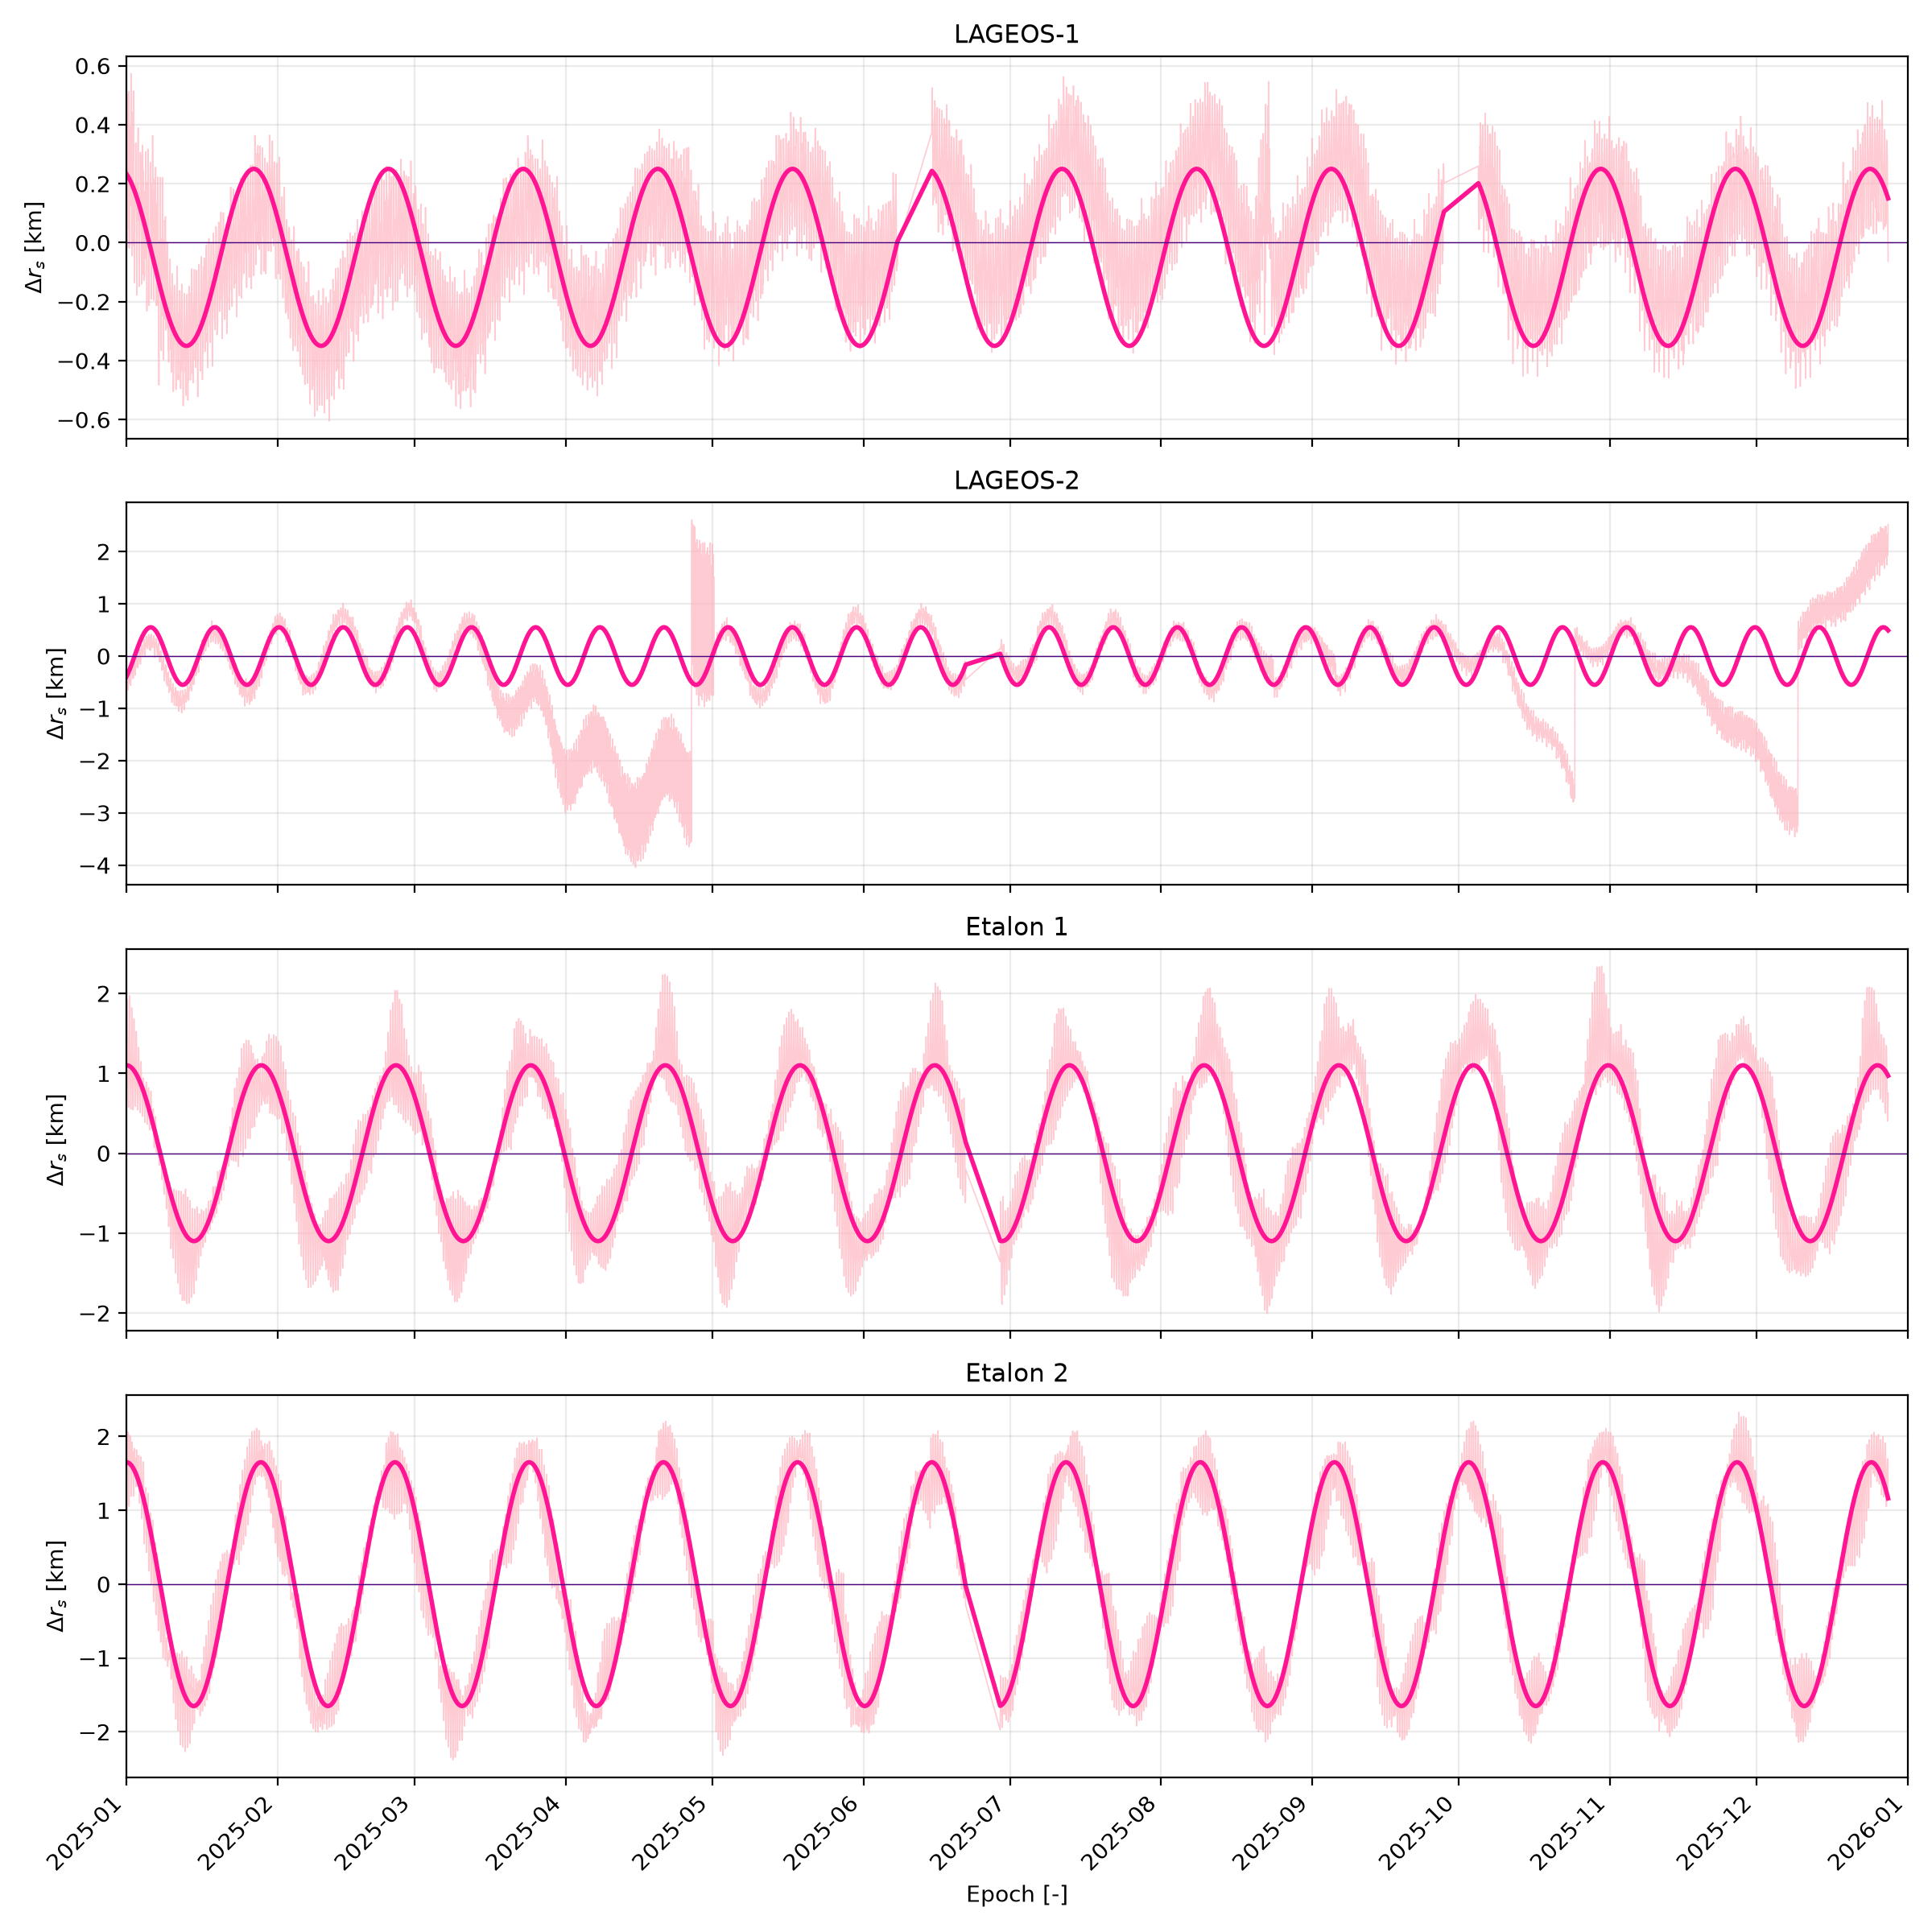

In [23]:
from IPython.display import Image, display
display(Image(filename="figures/along_track_2025.png", width=800))

### Bibliography

Hallgarten La Casta, M., Amato, D. (2024). _Debiasing of Two-Line Element Sets for Batch Least Squares Pseudo-Orbit Determination in MEO and GEO_.[https://arxiv.org/abs/2412.15793](https://arxiv.org/abs/2412.15793)